# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [ ]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — Gate C: gate-current sanity check (liveness + gross safety)

Recipe `device-init/gate-current-sanity-check`, four legs (TG to +7/−6 V, BG to
±4.5 V, other gates parked, Si = 0 V, B = 0, T = 1.13 K, drive 0.5 V / 100 MΩ
nominal at 13 Hz). Raw traces first, then the leakage read.


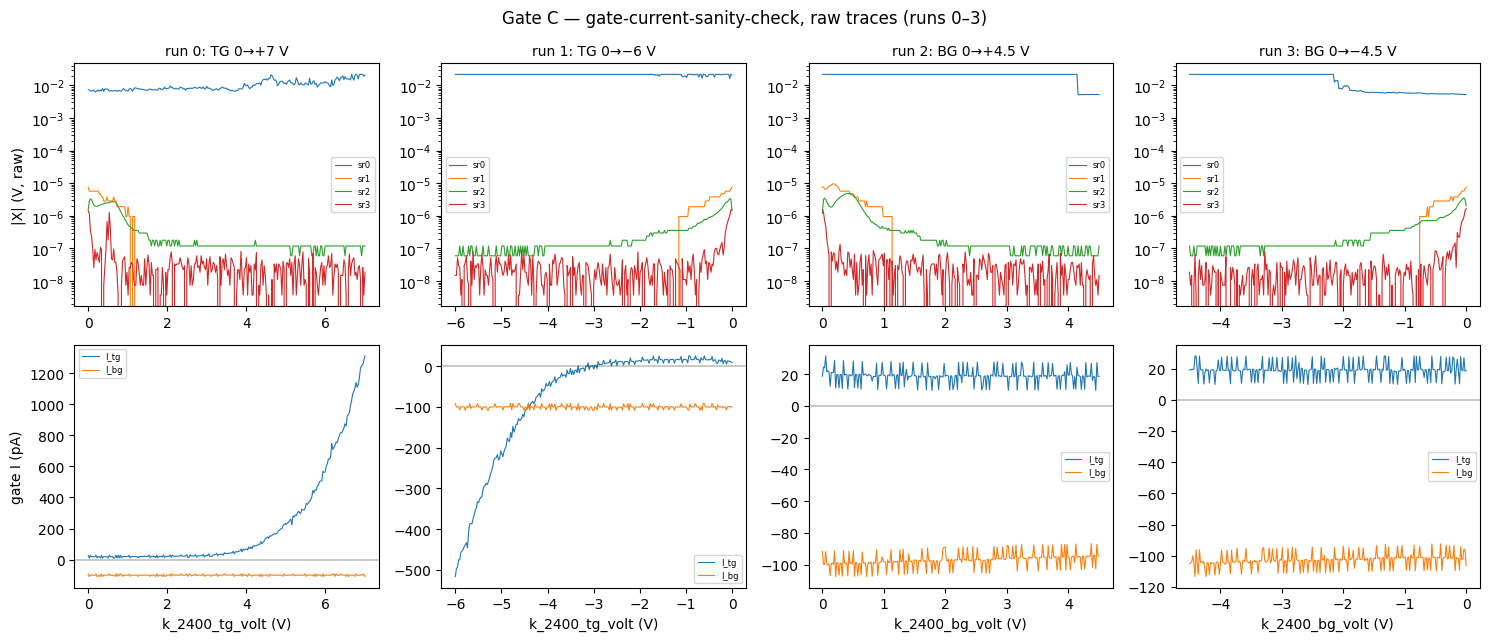

In [3]:
# Gate C — device-init/gate-current-sanity-check, runs 0-3. RAW FIRST.
# Top row: lock-in |X| (raw volts, no division — sr0 rides Ithaco output).
# Bottom row: both gate currents (pA).
legs = [(0, 'k_2400_tg_volt', 'TG 0→+7 V'), (1, 'k_2400_tg_volt', 'TG 0→−6 V'),
        (2, 'k_2400_bg_volt', 'BG 0→+4.5 V'), (3, 'k_2400_bg_volt', 'BG 0→−4.5 V')]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for j, (rid, vcol, leg) in enumerate(legs):
    r = run(rid)
    v = r.col_at(1)  # swept axis (also fp'd -> duplicate name; col_at disambiguates)
    ax = axes[0, j]
    for ch in ('sr0_X', 'sr1_X', 'sr2_X', 'sr3_X'):
        ax.plot(v, np.abs(r.col(ch)), lw=0.8, label=ch[:3])
    ax.set_yscale('log')
    ax.set_title(f'run {rid}: {leg}', fontsize=10)
    ax.legend(fontsize=6)
    if j == 0:
        ax.set_ylabel('|X| (V, raw)')
    ax = axes[1, j]
    ax.plot(v, r.col('k_2400_tg_curr') * 1e12, lw=0.8, label='I_tg')
    ax.plot(v, r.col('k_2400_bg_curr') * 1e12, lw=0.8, label='I_bg')
    ax.axhline(0, color='k', lw=0.3)
    ax.legend(fontsize=6)
    ax.set_xlabel(vcol + ' (V)')
    if j == 0:
        ax.set_ylabel('gate I (pA)')
fig.suptitle('Gate C — gate-current-sanity-check, raw traces (runs 0–3)')
fig.tight_layout()


In [4]:
# Gate C read — leakage profile per leg, offset-corrected.
# Flat instrument offsets (parked-gate reads): BG channel ~ -100 pA, TG ~ +20 pA (nplci=10).
for rid, vcol, icol, leg in [
        (0, 'k_2400_tg_volt', 'k_2400_tg_curr', 'TG +'),
        (1, 'k_2400_tg_volt', 'k_2400_tg_curr', 'TG -'),
        (2, 'k_2400_bg_volt', 'k_2400_bg_curr', 'BG +'),
        (3, 'k_2400_bg_volt', 'k_2400_bg_curr', 'BG -')]:
    r = run(rid)
    v, i = r.col_at(1), r.col(icol)  # swept axis via col_at (fp duplicate)
    i0 = np.median(i[np.abs(v) < 0.5])           # offset near 0 V
    exc = i - i0
    hot = np.abs(exc) > 1e-10                    # >100 pA above offset
    v_end = v[np.abs(v).argmax()]
    leak_end = exc[np.abs(v).argmax()]
    if hot.any():
        v_on = v[hot][np.abs(v[hot]).argmin()]   # smallest |V| exceeding 100 pA
        note = f'|I-I0| > 100 pA beyond {v_on:+.2f} V'
    else:
        note = 'clean (<100 pA above offset everywhere)'
    print(f'run {rid} ({leg}): offset {i0*1e12:+5.0f} pA | at {v_end:+.1f} V leak {leak_end*1e12:+6.0f} pA | {note}')


run 0 (TG +): offset   +19 pA | at +7.0 V leak  +1292 pA | |I-I0| > 100 pA beyond +4.45 V
run 1 (TG -): offset   +13 pA | at -6.0 V leak   -530 pA | |I-I0| > 100 pA beyond -4.30 V
run 2 (BG +): offset   -99 pA | at +4.5 V leak     +5 pA | clean (<100 pA above offset everywhere)
run 3 (BG -): offset  -101 pA | at -4.5 V leak     -4 pA | clean (<100 pA above offset everywhere)


**Gate C verdict — liveness PASS; TG range restriction found (stop-and-report).**

- **Alive**: every channel responds — sr1/sr2 show strong, smooth gate response
  with neutrality-like maxima near 0 V on both gates; sr3 (Hall) sits at noise
  floor at B = 0 as expected; drain passes current in all conditions. No dead
  pairs, no shared-node short.
- **TG leaks on both polarities**: |I_tg − offset| exceeds 100 pA beyond
  **+4.45 V / −4.30 V**, reaching **+1.29 nA at +7.0 V** and **−0.53 nA at
  −6.0 V** — exponential turn-up, leakage, not charging (charging floor is
  ~15–25 pA). Runs 0/1.
- **BG clean** to ±4.5 V both sides (< 100 pA above the flat −100 pA channel
  offset; runs 2/3). Offsets at nplci = 10: BG channel ≈ −100 pA, TG ≈ +20 pA
  — read leakage relative to these.
- **sr0 railed** at X = 21.8 mV (2e-2 V sensitivity) over much of runs 1–3 —
  drain-current trace clipped. Implied I ≥ 22 nA is inconsistent with the
  nominal 0.5 V / 100 MΩ = 5 nA chain: Ithaco gain dial vs the recorded −1e6,
  or the bias-resistor value, needs a rack check. Liveness read unaffected.
- **Recommendation pending operator ruling** (`gate-leakage-survey` is
  blocklisted this session): design all sweeps within **TG ∈ [−4.0, +4.0] V**
  (leakage < ~60 pA there), BG full ±4.5 V. SAFETIES validators stay as
  committed — this is a design cap, not a safety-surface change. Cell B
  (nplci reset) held until the ruling.


## Runs 4-7 — post-excursion health re-check vs runs 0-3 (reentry-baseline)
Four reduced-extent legs (TG to +/-4.0 V, BG to +/-4.5 V), identical acquisition. Checks: (1) leakage above own offset, (2) CNP-adjacent feature position shift, (3) trace-shape correlation (log-log), (4) amplitude scale ratio.

leg     leak_new  leak_ref  d_peak1  d_peak2  shape r1/r2  scale r1/r2
TG +         77p       50p   +0.00V   -0.06V  0.95/0.99  1.00/1.00
TG −         67p       63p   +0.00V   -0.01V  0.96/0.99  1.00/1.00
BG +         13p       13p   +0.02V   +0.02V  0.99/0.99  1.00/1.00
BG −         11p       12p   +0.00V   -0.02V  0.95/0.99  1.00/1.00


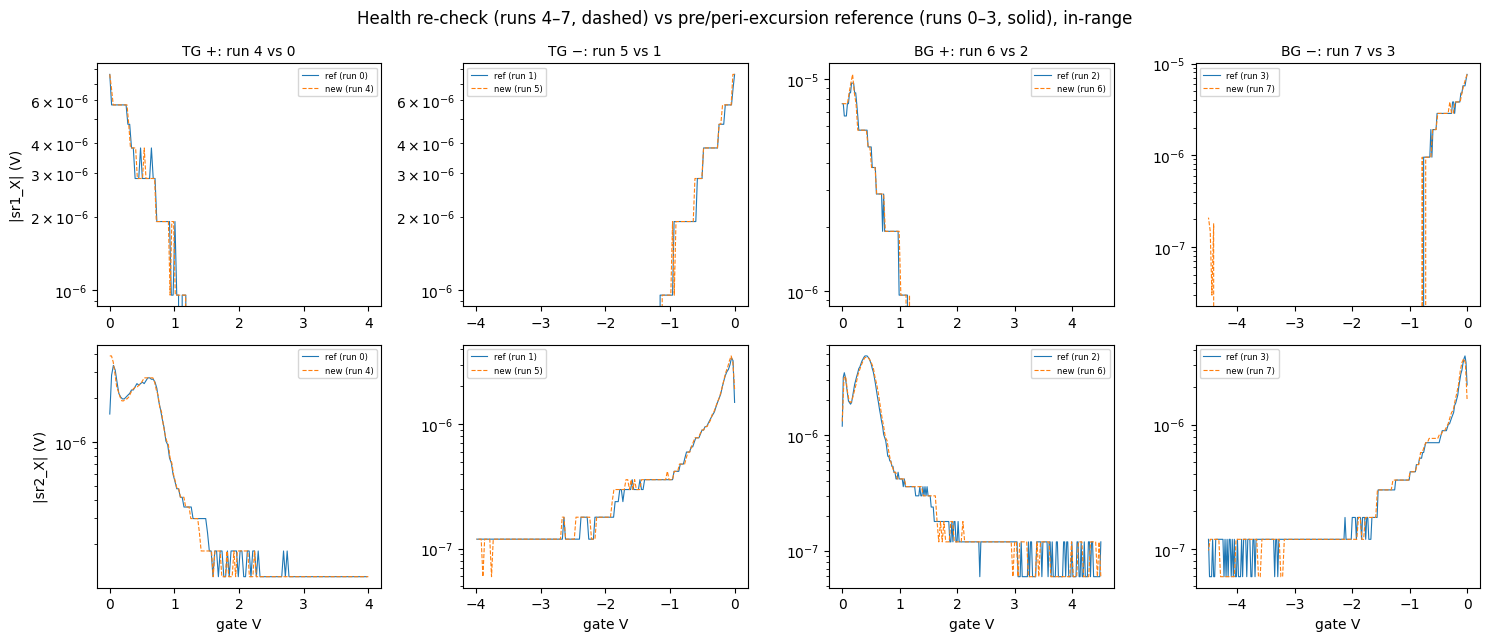

In [5]:
# Runs 4-7 vs runs 0-3 — post-excursion health comparison (reentry-baseline).
# Pairs: (health, reference): TG+ (4,0), TG- (5,1), BG+ (6,2), BG- (7,3).
# Reference restricted to the health leg's V range.
pairs = [(4, 0, 'TG +', 'k_2400_tg_curr'), (5, 1, 'TG −', 'k_2400_tg_curr'),
         (6, 2, 'BG +', 'k_2400_bg_curr'), (7, 3, 'BG −', 'k_2400_bg_curr')]

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
print(f"{'leg':6} {'leak_new':>9} {'leak_ref':>9} {'d_peak1':>8} {'d_peak2':>8} {'shape r1/r2':>12} {'scale r1/r2':>12}")
for j, (hid, rid, leg, icol) in enumerate(pairs):
    h, rr = run(hid), run(rid)
    vh, vr = h.col_at(1), rr.col_at(1)
    m = np.abs(vr) <= np.abs(vh).max() + 1e-6          # in-range slice of reference
    # 1) leakage above own offset
    def leak(r, v, i0mask):
        i = r.col(icol)
        i0 = np.median(i[np.abs(v) < 0.5])
        return np.abs(i - i0).max()
    lk_h, lk_r = leak(h, vh, None), np.abs(rr.col(icol)[m] - np.median(rr.col(icol)[np.abs(vr) < 0.5])).max()
    row = [f'{leg:6} {lk_h*1e12:8.0f}p {lk_r*1e12:8.0f}p']
    stats = []
    for k, ch in enumerate(('sr1_X', 'sr2_X')):
        xh, xr = np.abs(h.col(ch)), np.abs(rr.col(ch)[m])
        vrm = vr[m]
        # 2) feature position: |X| max within |V|<2 (CNP-adjacent feature)
        mh, mr = np.abs(vh) < 2, np.abs(vrm) < 2
        dpk = vh[mh][xh[mh].argmax()] - vrm[mr][xr[mr].argmax()]
        # 3) shape: correlation of log|X| on common grid
        xi = np.interp(vh, vrm[np.argsort(vrm)], xr[np.argsort(vrm)])
        ok = (xh > 1e-7) & (xi > 1e-7)
        shape = np.corrcoef(np.log(xh[ok]), np.log(xi[ok]))[0, 1]
        # 4) scale: median ratio where reference is above noise
        scale = np.median(xh[ok] / xi[ok])
        stats.append((dpk, shape, scale))
        ax = axes[k, j]
        ax.plot(vrm, xr, lw=0.8, label=f'ref (run {rid})')
        ax.plot(vh, xh, lw=0.8, ls='--', label=f'new (run {hid})')
        ax.set_yscale('log')
        if k == 0: ax.set_title(f'{leg}: run {hid} vs {rid}', fontsize=10)
        ax.set_ylabel(f'|{ch}| (V)') if j == 0 else None
        ax.legend(fontsize=6)
        if k == 1: ax.set_xlabel('gate V')
    print(row[0] + f' {stats[0][0]:+7.2f}V {stats[1][0]:+7.2f}V '
          f'{stats[0][1]:5.2f}/{stats[1][1]:4.2f} {stats[0][2]:5.2f}/{stats[1][2]:4.2f}')
fig.suptitle('Health re-check (runs 4–7, dashed) vs pre/peri-excursion reference (runs 0–3, solid), in-range')
fig.tight_layout()


**Health verdict — PASS on all four checks: the device survived the ±gate
excursion unchanged.**

| check | result |
|---|---|
| leakage floor | TG 77 / 67 pA max excess to ±4 V (ref in-range: 50 / 63 pA); BG 13 / 11 pA (ref 13 / 12 pA) — no new turn-up inside the window |
| feature positions | CNP-adjacent maxima shifted ≤ 0.06 V (≈ 1–2 steps) on sr1/sr2, all legs |
| trace shape | log-log correlation 0.95–0.99 per channel per leg; same feature set, no new structure |
| resistance scale | median amplitude ratio 1.00 on every channel/leg |

The overlay figure above shows ref (solid) vs re-check (dashed) essentially
point-for-point coincident. Conclusion: the +7 V / 1.3 nA and −6 V / 0.5 nA
excursions of runs 0/1 did not alter the device — leakage there was reversible
dielectric conduction, not damage. Operating recommendation stands: **TG design
cap ±4.0 V** (leakage < ~80 pA), BG full ±4.5 V; SAFETIES validators unchanged.
